In [ ]:
import requests
import json
import os
import urllib3
import boto3
from datetime import datetime

In [1]:
print("Final Project Code")

Final Project Code


In [1]:
print("This project focuses on traffic sign detection and recognition using computer vision and machine learning techniques. The goal of this project is to develop a system that can accurately identify and classify traffic signs from images or video streams, which can be useful for autonomous vehicles and driver assistance systems.")

This project focuses on traffic sign detection and recognition using computer vision and machine learning techniques. The goal of this project is to develop a system that can accurately identify and classify traffic signs from images or video streams, which can be useful for autonomous vehicles and driver assistance systems.


Create a histogram

We can create a histogram by using the histo() function


In [2]:
import matplotlib.pyplot as plt
def histo(data, bins=10, xlabel="Values", ylabel="Frequency", title="Histogram"):
    plt.hist(data, bins=bins, edgecolor="black")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

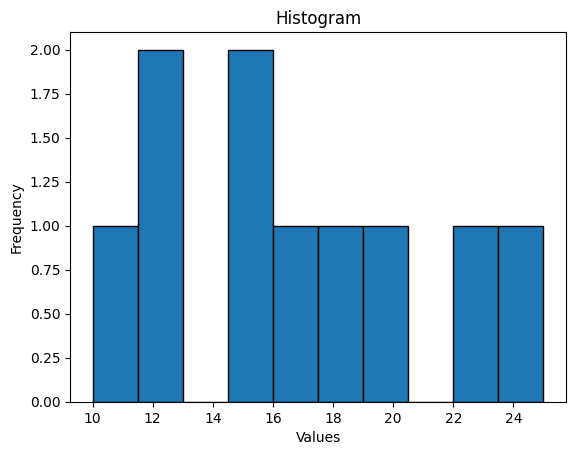

In [5]:
# Replace `data` with your numerical data
# Create your own bins, labels, and title as needed
data = [10, 12, 15, 12, 18, 20, 15, 17, 22, 25]

histo(data)

In [ ]:
s3_client = boto3.client('s3')

bucket_name = "uncc_traffic_data"

In [ ]:
def lambda_function(event, context):

     api_key = os.environ['TOMTOM_API_KEY']

     latitude = ["a", "b"] # fill in with the found values
     longitude = ["a", "b"]

     http = urllib3.PoolManager()

     for i in range(len(latitude)):
        url = f"https://tomtom.com{api_key}&point={latitude[i]},{longitude[i]}&unit=MPH"
        try:
            response = http.request('GET', url)
            if response.status_code==200:
                    data = json.loads(response.data.decode('utf-8'))
                    flow_data = data.get("flowSegmentData", {})

                    now = datetime.utcnow()
                    timestamp_str = now.isoformat()

                    traffic_record = {
                        "StationID": "", # Fill in later
                        "Timestamp": timestamp_str,
                        "current_speed": int(flow_data.get("currentSpeed",0)),
                        "free_flow_speed": int(flow_data.get("freeFlowSpeed",0)),
                        "current_delay": int(flow_data.get("currentDelay",0)),
                        "confidence": int(flow_data.get("confidence",0)) # for flags of when we shoudl somehow retrain?
                          
                    }

                    s3_key = f"raw_traffic/year={now.year}/month={now.strftime('%m')}/day={now.strftime('%d')}/traffic_{now.strftime('%H%M%S')}.json"

                    s3_client.put_object(
                        Bucket=bucket_name,
                        Key=s3_key,
                        Body=json.dumps(traffic_record),
                        ContentType='application/json'
                    )

                    print(f"Successfully uploaded data to s3://{bucket_name}/{s3_key}")
                    return{"statusCode": 200, "body": "Data uploaded to s3 successfully!"}
            return {"statusCode": response.status, "body": "Failure!"}
        except Exception as e:
             print(f"Error encountered: {e}")
             return ("statusCode": 201, "body": str(e))

            
def get_current_speed(latitude, longitude, api_key):
    url = f"https://tomtom.com"

    params = {
        'key': api_key,
        'point': f"{latitude},{longitude}",
        'unit': "MPH",
        "openLr": "false"
    }

    response = requests.get(url, params)

    if response.status_code==200:
        data = response.json()
        flow_data = data.get("flowSegmentData", {})

        data_we_want = {
            "current_speed": flow_data.get("currentSpeed"),
            "free_flow_speed": flow_data.get("freeFlowSpeed"),
            "current_delay": flow_data.get("currentDelay"),
            "confidence": flow_data.get("confidence") # for flags of when we shoudl somehow retrain?
        }

        return data_we_want
    else:
        print(f"Error in retrieving data: {response.status_code}")